In [1]:
#Upload dataset
from google.colab import files

uploaded = files.upload()


Saving nlp_dataset.csv to nlp_dataset.csv


In [2]:
# Load and explore your dataset
import os

print(os.listdir("/content"))


['.config', 'nlp_dataset.csv', 'sample_data']


In [3]:

import pandas as pd

df = pd.read_csv("/content/nlp_dataset.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()


Dataset shape: (5937, 2)

Column names:
['Comment', 'Emotion']

First 5 rows:


,Comment,Emotion
0,i seriously hate one subject to death but now ...,fear
1,im so full of life i feel appalled,anger
2,i sit here to write i start to dig out my feel...,fear
3,ive been really angry with r and i feel like a...,joy
4,i feel suspicious if there is no one outside l...,fear



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5937 entries, 0 to 5936
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Comment  5937 non-null   object
 1   Emotion  5937 non-null   object
dtypes: object(2)
memory usage: 92.9+ KB


Missing values:
Comment    0
Emotion    0
dtype: int64

Duplicate rows: 0

Unique emotions:
['fear' 'anger' 'joy']

Emotion distribution:
Emotion
anger    2000
joy      2000
fear     1937
Name: count, dtype: int64


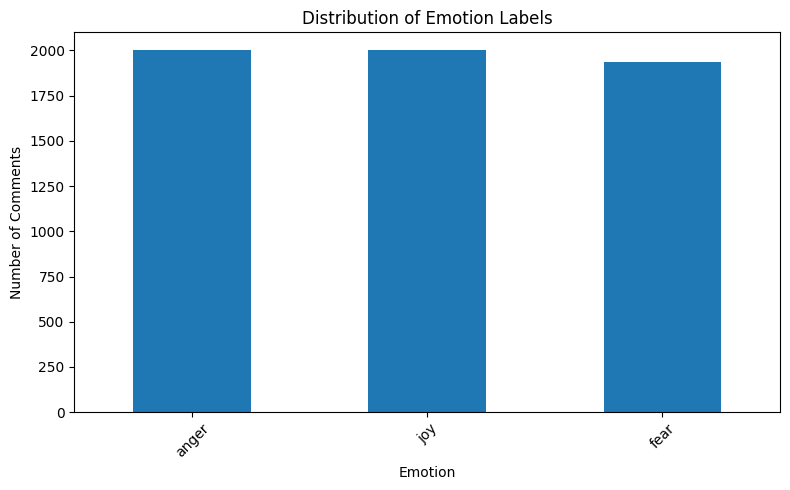

In [4]:
# Explore the emotion labels

# Check for missing values and duplicate rows
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# Check the emotion categories
print("\nUnique emotions:")
print(df["Emotion"].unique())

# Count examples in each emotion category
print("\nEmotion distribution:")
print(df["Emotion"].value_counts())

# Visualize the distribution
import matplotlib.pyplot as plt

df["Emotion"].value_counts().plot(
    kind="bar",
    figsize=(8, 5),
    title="Distribution of Emotion Labels"
)

plt.xlabel("Emotion")
plt.ylabel("Number of Comments")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Missing values: Confirm that there are no empty comments or labels.



Duplicate rows: Identify repeated records that could bias the model.



Unique emotions: Discover all the categories the model must learn.



Class distribution: Check whether some emotions have many more examples than others. This matters because accuracy alone can be misleading when classes are imbalanced.

In [5]:
# Text preprocessing

import re
import nltk

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# Keep negation words because they affect emotion meaning
stop_words = set(stopwords.words("english"))
stop_words -= {"no", "nor", "not", "never"}

def preprocess_text(text):
    # Convert text to lowercase
    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove punctuation, numbers, and special characters
    text = re.sub(r"[^a-z\s']", " ", text)

    # Tokenize the text
    tokens = word_tokenize(text)

    # Remove stopwords and very short tokens
    tokens = [
        word for word in tokens
        if word not in stop_words and len(word) > 1
    ]

    return " ".join(tokens)

# Apply preprocessing
df["Clean_Comment"] = df["Comment"].apply(preprocess_text)

# Compare original and cleaned text
display(df[["Comment", "Clean_Comment", "Emotion"]].head())


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


,Comment,Clean_Comment,Emotion
0,i seriously hate one subject to death but now ...,seriously hate one subject death feel reluctan...,fear
1,im so full of life i feel appalled,im full life feel appalled,anger
2,i sit here to write i start to dig out my feel...,sit write start dig feelings think afraid acce...,fear
3,ive been really angry with r and i feel like a...,ive really angry feel like idiot trusting firs...,joy
4,i feel suspicious if there is no one outside l...,feel suspicious no one outside like rapture ha...,fear


Lowercasing: Treats Happy and happy as the same word.



Cleaning: Removes URLs, punctuation, numbers, and unnecessary symbols.



Tokenization: Splits each sentence into individual words.



Stopword removal: Removes common words while preserving important negations such as not and never.

In [6]:
#Convert text into numerical features using TF-IDF

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Separate input text and target labels
X = df["Clean_Comment"]
y = df["Emotion"]

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# Create TF-IDF features
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training feature shape:", X_train_tfidf.shape)
print("Testing feature shape:", X_test_tfidf.shape)


Training samples: 4749
Testing samples: 1188
Training feature shape: (4749, 5000)
Testing feature shape: (1188, 5000)


In [7]:
#Train Naive Bayes and SVM

from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

# 1. Train the Naive Bayes model
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

# 2. Train the Support Vector Machine model
svm_model = LinearSVC(random_state=42)
svm_model.fit(X_train_tfidf, y_train)

# Generate predictions
nb_predictions = nb_model.predict(X_test_tfidf)
svm_predictions = svm_model.predict(X_test_tfidf)

print("Both models have been trained successfully!")
print("Naive Bayes predictions:", nb_predictions[:10])
print("SVM predictions:", svm_predictions[:10])


Both models have been trained successfully!
Naive Bayes predictions: ['joy' 'fear' 'anger' 'fear' 'fear' 'anger' 'fear' 'anger' 'anger' 'anger']
SVM predictions: ['joy' 'fear' 'anger' 'fear' 'fear' 'anger' 'fear' 'anger' 'anger' 'anger']


. Multinomial Naive Bayes
- A probabilistic classification algorithm based on Bayes' theorem.
- Commonly used for text classification because it works efficiently with sparse word-feature representations.
- Assumes features are conditionally independent given the class, which is a simplifying assumption.
2. Linear Support Vector Machine (SVM)
- Finds a decision boundary that separates emotion categories.
- Works well with high-dimensional, sparse TF-IDF text features.
- LinearSVC is a practical choice for text classification because it handles many features efficiently.

Model Comparison:


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro)
0,Naive Bayes,0.9091,0.9091,0.9092,0.9091
1,Linear SVM,0.9461,0.9461,0.9461,0.9461



Naive Bayes Classification Report:
              precision    recall  f1-score   support

       anger       0.91      0.91      0.91       400
        fear       0.90      0.92      0.91       388
         joy       0.91      0.90      0.91       400

    accuracy                           0.91      1188
   macro avg       0.91      0.91      0.91      1188
weighted avg       0.91      0.91      0.91      1188


Linear SVM Classification Report:
              precision    recall  f1-score   support

       anger       0.95      0.93      0.94       400
        fear       0.94      0.95      0.94       388
         joy       0.95      0.96      0.95       400

    accuracy                           0.95      1188
   macro avg       0.95      0.95      0.95      1188
weighted avg       0.95      0.95      0.95      1188



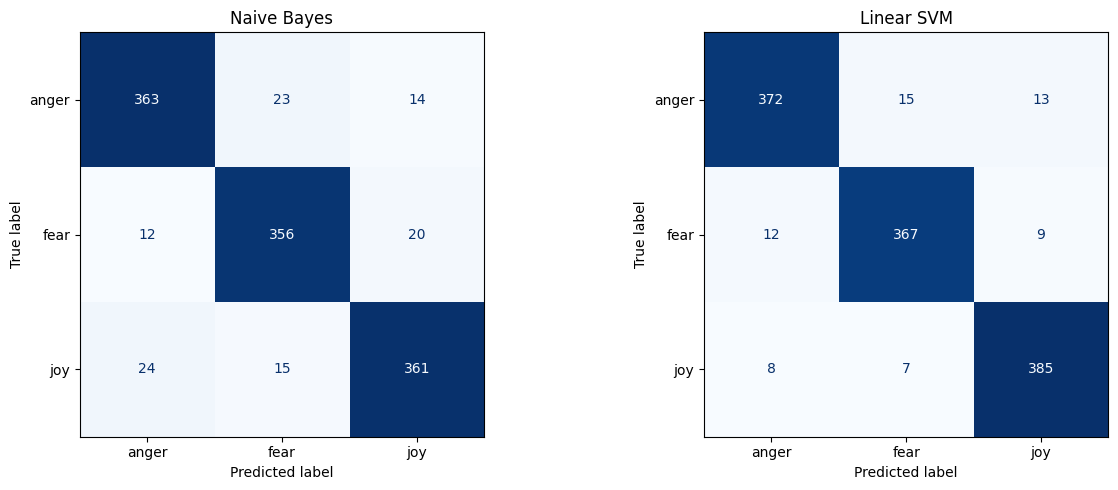

In [8]:
# Evaluate and compare the models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import pandas as pd
import matplotlib.pyplot as plt

# Calculate evaluation metrics
results = []

for model_name, predictions in [
    ("Naive Bayes", nb_predictions),
    ("Linear SVM", svm_predictions)
]:
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (Macro)": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "F1-Score (Macro)": f1_score(
            y_test, predictions, average="macro", zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print("Model Comparison:")
display(results_df.round(4))

# Detailed classification reports
print("\nNaive Bayes Classification Report:")
print(classification_report(
    y_test, nb_predictions, zero_division=0
))

print("\nLinear SVM Classification Report:")
print(classification_report(
    y_test, svm_predictions, zero_division=0
))

# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, name, predictions in [
    (axes[0], "Naive Bayes", nb_predictions),
    (axes[1], "Linear SVM", svm_predictions)
]:
    cm = confusion_matrix(y_test, predictions, labels=sorted(y.unique()))
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=sorted(y.unique())
    )
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()


#Model comparison and interpretation
Linear SVM performed better: its accuracy and macro F1-score are both 3.70 percentage points higher than Naive Bayes.



Performance across emotions is balanced: the SVM's F1-scores range from 0.94 for anger and fear to 0.95 for joy, based on your rounded report.



Naive Bayes is a strong baseline: it achieved about 91% accuracy and is computationally efficient.



Best model for this experiment: Linear SVM, because it achieved the strongest overall results on the held-out test set.

## Model Comparison and Conclusion

Two machine learning models, Multinomial Naive Bayes and Linear Support Vector Machine (SVM), were developed for emotion classification using TF-IDF features.

The dataset contained 5,937 text comments labelled as anger, fear, or joy. The data was divided into 80% training data and 20% testing data. Both models were evaluated using accuracy, macro precision, macro recall, and macro F1-score.

**Results:**

- **Multinomial Naive Bayes:** Achieved 90.91% accuracy and a macro F1-score of 90.91%.
- **Linear SVM:** Achieved 94.61% accuracy and a macro F1-score of 94.61%.

Linear SVM outperformed Naive Bayes by 3.70 percentage points in both accuracy and macro F1-score. Its strong performance makes it suitable for emotion classification because it can effectively learn decision boundaries from high-dimensional, sparse TF-IDF text features.

Naive Bayes also performed well and offers a computationally efficient baseline. However, based on the test results, Linear SVM is the preferred model for this experiment.

In conclusion, TF-IDF combined with Linear SVM successfully classified text comments into anger, fear, and joy categories with approximately 94.61% accuracy on the test set.